# Supervised Learning: Forecast station departures

We predict completed departures at each station. Notebook 01 builds the station-hour data, 02 checks shared inputs, 03 describes demand patterns, and 04 groups station behavior.

Notebook 05 compares historical baselines and supervised models, picks a forecast window using forward validation, and tests the result on April–June 2026. It also checks whether behavior features from 04 help and whether errors differ across 04's saved station groups.

## 1. Setup and shared inputs

Note: Changes to the training cutoff or the shared data require rerunning the matching notebooks.

In [ ]:
import sys
import json
import hashlib
import importlib.util
from pathlib import Path

PROJECT_FOLDER = "/content/drive/MyDrive/Milestone II"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")

    import subprocess
    for package, module in [
        ("numpy", "numpy"),
        ("pandas", "pandas"),
        ("pyarrow", "pyarrow"),
        ("matplotlib", "matplotlib"),
        ("scikit-learn", "sklearn"),
        ("scipy", "scipy"),
        ("threadpoolctl", "threadpoolctl"),
        ("xgboost", "xgboost")
    ]:
        if importlib.util.find_spec(module) is None:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "-q", package]
            )

ROOT = Path(PROJECT_FOLDER) if IN_COLAB else Path.cwd().resolve()

PROCESSED = ROOT / "data/processed"
SHARED = ROOT / "data/shared"

settings_path = ROOT / "project_settings.json"
if not settings_path.is_file():
    raise FileNotFoundError(f"Missing {settings_path}")

settings = json.loads(settings_path.read_text())

import numpy as np
import pandas as pd

STUDY_START = pd.Timestamp(settings["study_start"])
TRAIN_END = pd.Timestamp(settings["train_end"])
VAL_END = pd.Timestamp(settings["validation_end"])
TEST_END = pd.Timestamp(settings["test_end"])
PROFILE_AVAILABLE_FROM = pd.Timestamp(
    settings["forecast_profiles_available_from"]
)
CV_WINDOWS = settings["forward_validation_windows"]

assert STUDY_START < PROFILE_AVAILABLE_FROM < TRAIN_END < VAL_END < TEST_END
assert all(
    PROFILE_AVAILABLE_FROM < pd.Timestamp(a) < pd.Timestamp(b) <= VAL_END
    for a, b in CV_WINDOWS
)

if settings["timezone"] != "America/New_York":
    raise ValueError(
        "The prepared timestamps use Philadelphia local time."
    )

missing = [
    name for name in [
        "trips_clean.parquet",
        "station_hour.parquet",
        "stations.parquet"
    ]
    if not (PROCESSED / name).is_file()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files: {missing}. Run 01 first."
    )

RUN_STATION_GROUP_ANALYSIS = True

In [ ]:
import gc
import importlib.metadata
import json
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
import warnings
from copy import deepcopy
from matplotlib.colors import PowerNorm
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

def haversine_km(lat1, lon1, lat2, lon2):
    """Calculate straight-line distance between latitude/longitude pairs in kilometres."""
    lat1 = np.radians(np.asarray(lat1, dtype="float64"))
    lon1 = np.radians(np.asarray(lon1, dtype="float64"))
    lat2 = np.radians(np.asarray(lat2, dtype="float64"))
    lon2 = np.radians(np.asarray(lon2, dtype="float64"))
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6371.0088 * 2.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def save_figure(path, dpi=160, tight=True):
    """Save the figure, show it here and release it from memory."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if tight:
        plt.tight_layout()
    plt.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def check_shared_inputs():
    path = SHARED / "shared_manifest.json"
    if not path.is_file():
        raise FileNotFoundError("Run 02_shared_analysis_prep.ipynb once for these processed files.")
    contract = json.loads(path.read_text())
    if contract["settings"] != settings:
        raise ValueError("Project dates changed. Rerun 02, then the analyses.")
    for name, expected in contract["sources"].items():
        if file_hash(PROCESSED / name) != expected:
            raise ValueError(f"{name} changed. Rerun 02, then the analyses.")
    return contract

contract = check_shared_inputs()

In [ ]:
EXPORTS = ROOT / "results/unsupervised/forecast_export"

def load_station_groups():
    manifest_path = EXPORTS / "station_clusters_manifest.json"
    if not manifest_path.is_file():
        raise FileNotFoundError("Run the station-cluster export in notebook 04 first.")
    manifest = json.loads(manifest_path.read_text())
    if manifest.get("version") != 1 or manifest.get("settings") != settings:
        raise ValueError("The station export does not match the project settings.")
    if pd.Timestamp(manifest["training_end_exclusive"]) != TRAIN_END:
        raise ValueError("The station clusters use a different training period.")
    if manifest["shared_manifest_hash"] != file_hash(SHARED / "shared_manifest.json"):
        raise ValueError("The station export uses different shared inputs.")
    for name, digest in manifest["files"].items():
        path = EXPORTS / name
        if not path.is_file() or file_hash(path) != digest:
            raise ValueError(f"Station export missing or changed: {name}")
    groups = pd.read_parquet(EXPORTS / "station_clusters.parquet")
    required = ["station_id", "cluster_id", "station_cluster", "cluster_confidence"]
    if not set(required).issubset(groups.columns) or groups.station_id.duplicated().any():
        raise ValueError("Invalid station-cluster export: missing fields or repeated station IDs.")
    if len(groups) != manifest["n_stations"] or groups["station_cluster"].isna().any():
        raise ValueError("Station-cluster export and manifest do not match.")
    # Do not assume 04 still uses four clusters or the same labels.
    names = set(manifest.get("cluster_names", []))
    if names and not set(groups["station_cluster"]).issubset(names):
        raise ValueError("Station labels differ from the names in 04's manifest.")
    return groups[required].set_index("station_id"), manifest

station_groups, station_manifest = (load_station_groups() if RUN_STATION_GROUP_ANALYSIS
                                   else (None, None))

# Load columns used by forecasts, feature comparisons and timing checks.
PANEL_COLUMNS = [
    'station_id',
    'hour',
    'departures',
    'arrivals',
    'net_flow',
    'departures_next_hour',
    'temperature_c',
    'humidity',
    'precipitation_mm',
    'wind_speed_kmh',
    'us_aqi',
    'is_holiday',
    'holiday_name',
    'day_type',
    'sports_any',
    'sports_league',
    'km_to_sports',
    'near_sports',
    'bikes_available',
    'docks_available',
    'zero_bikes',
    'full_station',
    'rebalance_bikes_in',
    'rebalance_bikes_out',
    'service_events',
    'is_fifa_match_hour',
    'is_fifa_match_day',
    'is_septa_service_cut',
    'is_septa_fare_increase',
]
STATION_COLUMNS = [
    'station_id',
    'station_name',
    'go_live',
    'capacity',
    'lat',
    'lon',
    'district',
    'poi_cafe',
    'poi_restaurant',
    'poi_bar_pub',
    'poi_park',
    'poi_university',
    'poi_office',
    'poi_shop',
    'poi_hotel',
    'n_transit',
    'nearest_transit_m',
    'nearest_station_m',
    'n_stations_within_500m',
]
panel = pd.read_parquet(PROCESSED / "station_hour.parquet", columns=PANEL_COLUMNS)
stations = pd.read_parquet(PROCESSED / "stations.parquet", columns=STATION_COLUMNS)
for name in panel.select_dtypes(include="float64"):
    panel[name] = panel[name].astype("float32")
for name in panel.select_dtypes(include=["object", "string"]):
    panel[name] = panel[name].astype("string[pyarrow]")
panel = panel.loc[panel.hour.ge(STUDY_START) & panel.hour.lt(TEST_END)].copy()
count_history = panel.set_index(["station_id", "hour"])["departures"].copy()

## 2. Build forecast features

EDA (03) found meaningful hour-of-day and weekly patterns: correlations with hourly departures were 0.462, 0.472 and 0.489 for the one-hour, one-day and one-week lags. Wet hours saw fewer departures, but dock-status coverage was limited. That suggests starting with demand history, the calendar, and **prior-hour** weather rather than relying on incomplete status data for now.

Unesupervised learning (04) found differences in morning, evening, weekend and station flow. We measure those behaviors over each station's previous 28 days. Note that these are new, past-only features based on 04's findings, instead of the original trip-purpose labels. The labels saved by 04 are used later to review test errors.

At forecast time T, all observed demand and weather inputs end at T−1. Known calendar information can refer to T.

In [ ]:
def values_at_offset(frame: pd.DataFrame, columns: list[str], hour_offset: int) -> pd.DataFrame:
    """Return columns from hour + hour_offset, or null when that timestamp is not the adjacent row.

    frame must be sorted by station_id, then hour. The check is on the timestamp, so a gap in a
    station's history does not borrow the next available row.
    """
    grouped = frame.groupby("station_id", sort=False)
    neighbor_hour = grouped["hour"].shift(-hour_offset)
    expected = frame["hour"] + pd.Timedelta(hours=hour_offset)
    valid = neighbor_hour.eq(expected)
    return grouped[columns].shift(-hour_offset).where(valid)


def assert_values_match(
    station_id: pd.Series,
    hour: pd.Series,
    actual: pd.Series,
    panel_keys: pd.DataFrame,
    panel_column: str,
    label: str,
) -> None:
    """Each modeling value equals the panel value at the same station and hour."""
    check = pd.DataFrame(
        {
            "station_id": station_id.to_numpy(),
            "hour": pd.to_datetime(hour).to_numpy(),
            "actual": actual.to_numpy(),
        }
    ).merge(panel_keys, on=["station_id", "hour"], how="left", validate="many_to_one")
    if len(check) != len(actual):
        raise RuntimeError(f"{label} alignment changed the row count")
    expected = check[panel_column]
    observed = check["actual"]
    if pd.api.types.is_numeric_dtype(pd.Series(observed)) or pd.api.types.is_numeric_dtype(expected):
        ok = np.allclose(
            pd.to_numeric(observed, errors="coerce").to_numpy(dtype="float64"),
            pd.to_numeric(expected, errors="coerce").to_numpy(dtype="float64"),
            equal_nan=True,
            rtol=0,
            atol=0,
        )
    else:
        ok = observed.astype("string").fillna("<NA>").equals(expected.astype("string").fillna("<NA>"))
    if not ok:
        raise RuntimeError(f"{label} does not match the panel at the claimed hour")


_gap = pd.DataFrame(
    {
        "station_id": [1, 1, 1, 2],
        "hour": pd.to_datetime(
            ["2024-01-01 00:00", "2024-01-01 01:00", "2024-01-01 03:00", "2024-01-01 02:00"]
        ),
        "departures": [10, 11, 13, 50],
    }
)
_forward = values_at_offset(_gap, ["departures"], 1)
_back = values_at_offset(_gap, ["departures"], -1)
assert _forward["departures"].tolist()[0] == 11
assert _forward["departures"].iloc[1:].isna().all()
assert _back["departures"].isna().tolist() == [True, False, True, True]
assert _back["departures"].iloc[1] == 10


# Target-hour boundaries are inclusive of the first instant and exclusive of the end instant.
# TRAIN_END, VAL_END and TEST_END are read from the project settings.


# Same windows as 01_data_joining.ipynb.
SEPTA_CUT_START = pd.Timestamp("2025-08-24")
SEPTA_CUT_END = pd.Timestamp("2025-09-13 23:00:00")
SEPTA_FARE_START = pd.Timestamp("2025-09-14")
FIFA_MATCHES = [
    ("2026-06-14 19:00", "Cote d'Ivoire vs Ecuador"),
    ("2026-06-19 20:30", "Brazil vs Haiti"),
    ("2026-06-22 17:00", "France vs Iraq"),
    ("2026-06-25 16:00", "Curacao vs Cote d'Ivoire"),
    ("2026-06-27 17:00", "Croatia vs Ghana"),
    ("2026-07-04 17:00", "Round of 16"),
]
LFF = (39.900833, -75.167500)
NEAR_LFF_KM = 1.5

match_hours: set[pd.Timestamp] = set()
for kickoff, _label in FIFA_MATCHES:
    start = pd.Timestamp(kickoff)
    end = (start + pd.Timedelta(hours=3)).floor("h")
    match_hours.update(pd.date_range(start.floor("h"), end, freq="h"))
FIFA_DAYS = {pd.Timestamp(kickoff).normalize() for kickoff, _label in FIFA_MATCHES}

BOOL_AS_FLOAT = ["is_holiday", "sports_any", "near_sports", "zero_bikes", "full_station"]
TARGET_HOUR_NUMERIC = ["temperature_c", "is_holiday", "sports_any", "km_to_sports", "near_sports"]
TARGET_HOUR_TEXT = ["holiday_name", "day_type", "sports_league"]
PREVIOUS_HOUR_STATUS = {
    "bikes_available": "bikes_available_lag",
    "docks_available": "docks_available_lag",
    "zero_bikes": "zero_bikes_lag",
    "full_station": "full_station_lag",
    "rebalance_bikes_in": "rebalance_bikes_in_lag",
    "rebalance_bikes_out": "rebalance_bikes_out_lag",
    "service_events": "service_events_lag",
}

CALENDAR_FEATURES = ["hour_of_day", "day_of_week", "month", "is_weekend", "is_holiday", "holiday_name"]
DEMAND_FEATURES = [
    "lag_1",
    "lag_24",
    "lag_168",
    "same_hour_mean_4w",
    "same_hour_weeks",
    "arrivals_lag",
    "net_flow_lag",
]
# Use the previous completed hour. The observed target-hour weather is not known at T.
PAST_WEATHER = ["temperature_c", "humidity", "precipitation_mm", "wind_speed_kmh", "us_aqi"]
WEATHER_FEATURES = [name + "_lag" for name in PAST_WEATHER]
SPORTS_FEATURES = [
    "sports_any",
    "near_sports",
    "km_to_sports",
    "sports_league",
]
POI_FEATURES = [
    "poi_cafe",
    "poi_restaurant",
    "poi_bar_pub",
    "poi_park",
    "poi_university",
    "poi_office",
    "poi_shop",
    "poi_hotel",
]
STATION_CONTEXT_FEATURES = [
    "station_id",
    "district",
    "capacity",
    "station_age_days",
    "context_missing",
    *POI_FEATURES,
    "n_transit",
    "nearest_transit_m",
    "nearest_station_m",
    "n_stations_within_500m",
]
# Keep location and age in the main model. Other context is a feature comparison.
STATION_FEATURES = ["station_id", "lat", "lon", "station_age_days"]
CONTEXT_FEATURES = [name for name in STATION_CONTEXT_FEATURES if name not in STATION_FEATURES]

# Recent station behavior follows the trip and station patterns examined in 04.
# Each summary ends at H, the last observed hour, when predicting T = H + 1.
BEHAVIOR_FEATURES = [
    "am_departure_share_28d",
    "pm_departure_share_28d",
    "weekend_departure_share_28d",
    "am_net_flow_28d",
    "pm_net_flow_28d",
    "observed_hours_28d",
]

def historical_behavior(frame):
    """Summarize the previous 28 days at each station, including the last known hour."""
    result = pd.DataFrame(index=frame.index, columns=BEHAVIOR_FEATURES, dtype="float32")
    for _, group in frame.groupby("station_id", sort=False):
        time_index = pd.DatetimeIndex(group["hour"])
        weekday = time_index.dayofweek < 5
        am = weekday & (time_index.hour >= 6) & (time_index.hour <= 9)
        pm = weekday & (time_index.hour >= 15) & (time_index.hour <= 18)
        weekend = time_index.dayofweek >= 5
        departures = group["departures"].fillna(0).to_numpy(dtype=float)
        arrivals = group["arrivals"].fillna(0).to_numpy(dtype=float)
        values = pd.DataFrame({
            "departures": departures,
            "am_dep": departures * am,
            "pm_dep": departures * pm,
            "weekend_dep": departures * weekend,
            "am_arr": arrivals * am,
            "pm_arr": arrivals * pm,
            "am_tot": departures * am,
            "pm_tot": departures * pm,
            "observed_hours": np.ones(len(group)),
        }, index=time_index)
        recent = values.rolling("28D", min_periods=1).sum()
        total = recent["departures"].replace(0, np.nan)
        am_total = recent["am_arr"] + recent["am_tot"]
        pm_total = recent["pm_arr"] + recent["pm_tot"]
        features = pd.DataFrame({
            "am_departure_share_28d": recent["am_dep"] / total,
            "pm_departure_share_28d": recent["pm_dep"] / total,
            "weekend_departure_share_28d": recent["weekend_dep"] / total,
            "am_net_flow_28d": (recent["am_arr"] - recent["am_tot"]) / am_total.replace(0, np.nan),
            "pm_net_flow_28d": (recent["pm_arr"] - recent["pm_tot"]) / pm_total.replace(0, np.nan),
            "observed_hours_28d": recent["observed_hours"],
        })
        result.loc[group.index, BEHAVIOR_FEATURES] = features.to_numpy(dtype="float32")
    return result

# A changed future hour must not change features for an earlier forecast.
_demo = pd.DataFrame({
    "station_id": [1] * 48 + [2] * 48,
    "hour": list(pd.date_range("2024-01-01", periods=48, freq="h")) * 2,
    "departures": [1.0] * 96,
    "arrivals": [2.0] * 96,
})
_before = historical_behavior(_demo)
_changed = _demo.copy()
_changed.loc[30:, "departures"] = 100
_after = historical_behavior(_changed)
pd.testing.assert_frame_equal(_before.loc[:29], _after.loc[:29])
del _demo, _before, _after, _changed

CASE_FLAGS = ["is_fifa_match_hour", "is_fifa_match_day", "is_septa_service_cut", "is_septa_fare_increase"]
CATEGORICAL_FEATURES = [
    "station_id",
    "district",
    "holiday_name",
    "sports_league",
    "station_cluster",
]
FEATURE_COLUMNS = [
    *CALENDAR_FEATURES,
    *DEMAND_FEATURES,
    *WEATHER_FEATURES,
    *STATION_FEATURES,
]
ABLATION_COLUMNS = [
    "bikes_available_lag",
    "docks_available_lag",
    "zero_bikes_lag",
    "full_station_lag",
    "status_observed",
    "rebalance_bikes_in_lag",
    "rebalance_bikes_out_lag",
    "service_events_lag",
]
META_COLUMNS = [
    "station_id",
    "station_name",
    "target_hour",
    "y",
    "baseline_lag_168",
    "is_fifa_match_hour",
    "is_fifa_match_day",
    "is_septa_service_cut",
    "is_septa_fare_increase",
    "near_lff",
    "km_to_lff",
    "lat",
    "lon",
]

# Build the original modeling rows in station batches to limit temporary memory use.
# Every station keeps its complete time history, so lags never cross batch boundaries.
def prepare_model_rows(panel, stations):
    panel = panel.sort_values(["station_id", "hour"], kind="mergesort").reset_index(drop=True)
    if panel.duplicated(["station_id", "hour"]).any():
        raise RuntimeError("station-hour key is not unique")
    panel["station_id"] = panel["station_id"].astype("int32")
    for column in BOOL_AS_FLOAT:
        panel[column] = panel[column].astype("float64")

    # Aligning calendar, weather, and sports to the target hour.
    target_numeric = values_at_offset(panel, TARGET_HOUR_NUMERIC, 1)
    target_text = values_at_offset(panel, TARGET_HOUR_TEXT, 1)

    # Building demand lags.
    # T = H + 1. Departures at T - 24h are stored on row H - 23h.
    lag_24 = values_at_offset(panel, ["departures"], -23)["departures"]
    weekly = {
        weeks: values_at_offset(panel, ["departures"], 1 - 168 * weeks)["departures"]
        for weeks in range(1, 5)
    }
    weekly_frame = pd.DataFrame(weekly)

    keep = panel["departures_next_hour"].notna()
    model_frame = pd.DataFrame(index=panel.index[keep])
    model_frame["station_id"] = panel["station_id"]
    model_frame["target_hour"] = panel["hour"] + pd.Timedelta(hours=1)
    model_frame["y"] = panel["departures_next_hour"]
    model_frame["lag_1"] = panel["departures"]
    model_frame["lag_24"] = lag_24
    model_frame["lag_168"] = weekly[1]
    model_frame["same_hour_mean_4w"] = weekly_frame.mean(axis=1, skipna=True)
    model_frame["same_hour_weeks"] = weekly_frame.notna().sum(axis=1).astype("int8")
    model_frame["arrivals_lag"] = panel["arrivals"]
    model_frame["net_flow_lag"] = panel["net_flow"]
    behavior = historical_behavior(panel)
    for column in BEHAVIOR_FEATURES:
        model_frame[column] = behavior[column]
    for column in TARGET_HOUR_NUMERIC:
        model_frame[column] = target_numeric[column]
    for column in TARGET_HOUR_TEXT:
        model_frame[column] = target_text[column]
    # Weather from H is available when the forecast for T = H + 1 begins.
    for column in PAST_WEATHER:
        model_frame[column + "_lag"] = panel[column]
    for source, name in PREVIOUS_HOUR_STATUS.items():
        model_frame[name] = panel[source]
    # Saved Boolean flags alone cannot distinguish a missing reading from False.
    model_frame["zero_bikes_lag"] = model_frame["zero_bikes_lag"].where(panel["bikes_available"].notna())
    model_frame["full_station_lag"] = model_frame["full_station_lag"].where(panel["docks_available"].notna())
    model_frame["status_observed"] = model_frame["bikes_available_lag"].notna().astype("float64")

    # Checking that y and the lags point at the hours they claim.
    history = panel[["station_id", "hour", "departures", "arrivals", "temperature_c", "day_type"]]
    assert_values_match(model_frame["station_id"], model_frame["target_hour"], model_frame["y"], history, "departures", "y")
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"] - pd.Timedelta(hours=1),
        model_frame["lag_1"],
        history,
        "departures",
        "lag_1",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"] - pd.Timedelta(hours=1),
        model_frame["arrivals_lag"],
        history,
        "arrivals",
        "arrivals_lag",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"] - pd.Timedelta(hours=24),
        model_frame["lag_24"],
        history,
        "departures",
        "lag_24",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"] - pd.Timedelta(hours=168),
        model_frame["lag_168"],
        history,
        "departures",
        "lag_168",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"] - pd.Timedelta(hours=672),
        weekly[4].loc[model_frame.index],
        history,
        "departures",
        "four-week lag",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"],
        model_frame["temperature_c"],
        history,
        "temperature_c",
        "temperature",
    )
    assert_values_match(
        model_frame["station_id"],
        model_frame["target_hour"],
        model_frame["day_type"],
        history,
        "day_type",
        "day_type",
    )
    if model_frame["temperature_c"].isna().any() or model_frame["day_type"].isna().any():
        raise RuntimeError("Target-hour weather or calendar is missing for a row with a defined target")
    expected_mean = weekly_frame.loc[model_frame.index].mean(axis=1, skipna=True)
    if not np.allclose(
        model_frame["same_hour_mean_4w"].to_numpy(dtype="float64"),
        expected_mean.to_numpy(dtype="float64"),
        equal_nan=True,
        rtol=0,
        atol=0,
    ):
        raise RuntimeError("same_hour_mean_4w is not the mean of the four weekly lags")
    # Alignment checks passed.

    model_frame["hour_of_day"] = model_frame["target_hour"].dt.hour.astype("int8")
    model_frame["day_of_week"] = model_frame["target_hour"].dt.dayofweek.astype("int8")
    model_frame["month"] = model_frame["target_hour"].dt.month.astype("int8")
    model_frame["is_weekend"] = model_frame["target_hour"].dt.dayofweek.ge(5).astype("float64")
    model_frame["is_fifa_match_hour"] = model_frame["target_hour"].isin(pd.DatetimeIndex(sorted(match_hours)))
    model_frame["is_fifa_match_day"] = model_frame["target_hour"].dt.normalize().isin(FIFA_DAYS)
    model_frame["is_septa_service_cut"] = model_frame["target_hour"].between(SEPTA_CUT_START, SEPTA_CUT_END)
    model_frame["is_septa_fare_increase"] = model_frame["target_hour"].ge(SEPTA_FARE_START)
    model_frame["baseline_lag_168"] = model_frame["lag_168"]

    model_frame["holiday_name"] = model_frame["holiday_name"].fillna("none")
    model_frame["sports_league"] = model_frame["sports_league"].fillna("none")

    static = stations.copy()
    static["station_id"] = static["station_id"].astype("int32")
    static = static.drop_duplicates("station_id")
    model_frame = model_frame.reset_index(drop=True).merge(static, on="station_id", how="left")
    model_frame["context_missing"] = model_frame["district"].isna().astype("float64")
    model_frame["district"] = model_frame["district"].fillna("unknown")
    model_frame["station_age_days"] = (
        model_frame["target_hour"] - model_frame["go_live"]
    ) / pd.Timedelta(days=1)
    model_frame["km_to_lff"] = haversine_km(
        model_frame["lat"], model_frame["lon"], LFF[0], LFF[1]
    )
    model_frame["near_lff"] = np.where(
        model_frame["km_to_lff"].notna(),
        model_frame["km_to_lff"].le(NEAR_LFF_KM).astype("float64"),
        np.nan,
    )
    model_frame = model_frame.drop(columns=["go_live"])

    ordered = list(
        dict.fromkeys([*META_COLUMNS, *FEATURE_COLUMNS, *ABLATION_COLUMNS,
                          *SPORTS_FEATURES, *CONTEXT_FEATURES, *BEHAVIOR_FEATURES])
    )
    missing_columns = [column for column in ordered if column not in model_frame.columns]
    if missing_columns:
        raise RuntimeError(f"Modeling frame is missing {missing_columns}")
    model_frame = model_frame[ordered].copy()
    if model_frame.duplicated(["station_id", "target_hour"]).any():
        raise RuntimeError("Modeling frame has duplicate station-target hours")
    if model_frame["y"].isna().any():
        raise RuntimeError("y still has missing rows")

    # The saved panel remains the reference for case-study dates.
    case_reference = panel[["station_id", "hour", *CASE_FLAGS]]
    for flag in CASE_FLAGS:
        assert_values_match(model_frame.station_id, model_frame.target_hour, model_frame[flag],
                            case_reference[["station_id", "hour", flag]], flag, flag)
    del case_reference

    # Text comparisons above use strings; numeric predictors can now be stored more compactly.
    for column in model_frame.select_dtypes(include="float64"):
        model_frame[column] = model_frame[column].astype("float32")
    for column in model_frame.select_dtypes(include=["object", "string"]):
        model_frame[column] = model_frame[column].astype("string[pyarrow]")
    del panel, target_numeric, target_text, lag_24, weekly, weekly_frame, history, static, behavior
    gc.collect()
    return model_frame

station_ids = sorted(panel.station_id.unique())
model_parts = []
for first in range(0, len(station_ids), 40):
    batch_ids = station_ids[first:first + 40]
    model_parts.append(prepare_model_rows(panel.loc[panel.station_id.isin(batch_ids)].copy(), stations))
model_frame = pd.concat(model_parts, ignore_index=True)
del model_parts, panel, stations
gc.collect()
fifa_hours = model_frame.loc[model_frame["is_fifa_match_hour"], "target_hour"]
if fifa_hours.empty:
    raise RuntimeError("The joined panel has no June 2026 match hours. Check notebook 01.")


# Suppress dispatch inputs that depend on station names still needing review.
dispatch_columns = list(PREVIOUS_HOUR_STATUS.values())[4:]
uncertain_dispatch = model_frame.station_id.isin(contract["uncertain_dispatch_station_ids"])
if not contract["dispatch_report_available"]:
    uncertain_dispatch[:] = True
model_frame.loc[uncertain_dispatch, dispatch_columns] = np.nan

## 3. Check the training data

Time splits follow the shared settings: historical fitting, January–March 2026 validation, and April–June 2026 test. We inspect missing inputs before fitting. Numeric filling is learned from training rows only, inside each model pipeline. Missing dock readings stay missing, not zero.

In [ ]:
target_hour = model_frame["target_hour"]
train_mask = target_hour.lt(TRAIN_END)
val_mask = target_hour.ge(TRAIN_END) & target_hour.lt(VAL_END)
test_mask = target_hour.ge(VAL_END) & target_hour.lt(TEST_END)
split_masks = {"Train": train_mask, "Validation": val_mask, "Test": test_mask}

if not (train_mask | val_mask | test_mask).all():
    raise RuntimeError("The time split does not cover every modeling row")
if ((train_mask & val_mask) | (val_mask & test_mask) | (train_mask & test_mask)).any():
    raise RuntimeError("The time split overlaps itself")

# Check event placement before using these flags to interpret model errors.
septa_cut_mask = model_frame["is_septa_service_cut"].astype(bool)
fifa_mask = model_frame["is_fifa_match_hour"].astype(bool)
if not septa_cut_mask.any() or not train_mask.loc[septa_cut_mask].all():
    raise RuntimeError("SEPTA cut rows are not all inside the training split")
if not fifa_mask.any() or not test_mask.loc[fifa_mask].all():
    raise RuntimeError("FIFA match hours are not all inside the test split")
if (val_mask & (fifa_mask | septa_cut_mask)).any():
    raise RuntimeError("Validation contains FIFA match hours or the SEPTA cut")

non_numeric = [
    column for column in FEATURE_COLUMNS
    if column not in CATEGORICAL_FEATURES
    and not pd.api.types.is_numeric_dtype(model_frame[column])
]
if non_numeric:
    raise RuntimeError(f"These feature columns are neither numeric nor categorical: {non_numeric}")


def split_row(name: str, mask: pd.Series) -> dict:
    # The summary needs only these columns, not another copy of every feature.
    columns = ["station_id", "target_hour", "y", "is_fifa_match_hour", "is_septa_service_cut"]
    part = model_frame.loc[mask, columns]
    return {
        "split": name.lower(),
        "rows": len(part),
        "stations": int(part["station_id"].nunique()),
        "target_start": part["target_hour"].min(),
        "target_end": part["target_hour"].max(),
        "mean_departures": part["y"].mean(),
        "zero_share": float(part["y"].eq(0).mean()),
        "fifa_match_rows": int(part["is_fifa_match_hour"].sum()),
        "septa_cut_rows": int(part["is_septa_service_cut"].sum()),
    }


summary = pd.DataFrame([split_row(name, mask) for name, mask in split_masks.items()])
assert summary["rows"].sum() == len(model_frame), "Split counts do not match the modeling table"
display(summary)


# These are coverage diagnostics for the full training period. The encoders below
# still learn their categories separately from the sample used in each fit.
unseen_rows = []
for column in [name for name in CATEGORICAL_FEATURES if name in FEATURE_COLUMNS]:
    training_levels = model_frame.loc[train_mask, column].dropna().unique()
    for label in ["Validation", "Test"]:
        values = model_frame.loc[split_masks[label], column]
        unseen = values.notna() & ~values.isin(training_levels)
        unseen_rows.append({
            "split": label,
            "feature": column,
            "unseen_levels": int(values.loc[unseen].nunique()),
            "rows": int(unseen.sum()),
        })
unseen_categories = pd.DataFrame(unseen_rows)


early_live = model_frame["station_age_days"].lt(0).mean()


# Check missingness directly from the modeling table. Status is included here
# because its limited coverage matters for the later feature comparison.
coverage_columns = list(dict.fromkeys(FEATURE_COLUMNS + ABLATION_COLUMNS + SPORTS_FEATURES + CONTEXT_FEATURES + BEHAVIOR_FEATURES))
missing_by_split = pd.DataFrame({
    label: {
        column: model_frame.loc[mask, column].isna().mean()
        for column in coverage_columns
    }
    for label, mask in split_masks.items()
}).T
display((missing_by_split.loc[:, missing_by_split.max().gt(0)] * 100).round(1))

,split,rows,stations,target_start,target_end,mean_departures,zero_share,fifa_match_rows,septa_cut_rows
0,train,4640783,316,2024-01-01 01:00:00,2025-12-31 23:00:00,0.566146,0.702576,0,143277
1,validation,640874,304,2026-01-01 00:00:00,2026-03-31 23:00:00,0.321292,0.800936,0,0
2,test,668043,314,2026-04-01 00:00:00,2026-06-30 23:00:00,0.723494,0.658230,6204,0


,lag_24,lag_168,same_hour_mean_4w,lat,lon,bikes_available_lag,docks_available_lag,zero_bikes_lag,full_station_lag,rebalance_bikes_in_lag,...,poi_hotel,n_transit,nearest_transit_m,nearest_station_m,n_stations_within_500m,am_departure_share_28d,pm_departure_share_28d,weekend_departure_share_28d,am_net_flow_28d,pm_net_flow_28d
Train,0.2,1.1,1.1,0.0,0.0,75.4,75.4,75.4,75.4,0.6,...,0.2,0.2,24.1,12.3,0.2,1.5,1.5,1.5,2.9,1.8
Validation,0.0,0.2,0.2,0.0,0.0,72.5,72.5,72.5,72.5,0.3,...,0.0,0.0,23.6,15.8,0.0,1.5,1.5,1.5,7.3,2.6
Test,0.0,0.4,0.4,0.0,0.0,61.4,61.4,61.4,61.4,0.3,...,0.0,0.0,24.6,17.1,0.0,0.5,0.5,0.5,1.7,0.7


## 4. Historical baselines and candidate models

The EDA lag correlations make historical averages a serious benchmark. Compare the station/weekday/hour mean, previous week, and previous four weeks against Poisson regression, XGBoost and a small neural network. For the initial model search, use median filling with a missing-value indicator. We test that choice later instead of assuming it is best.

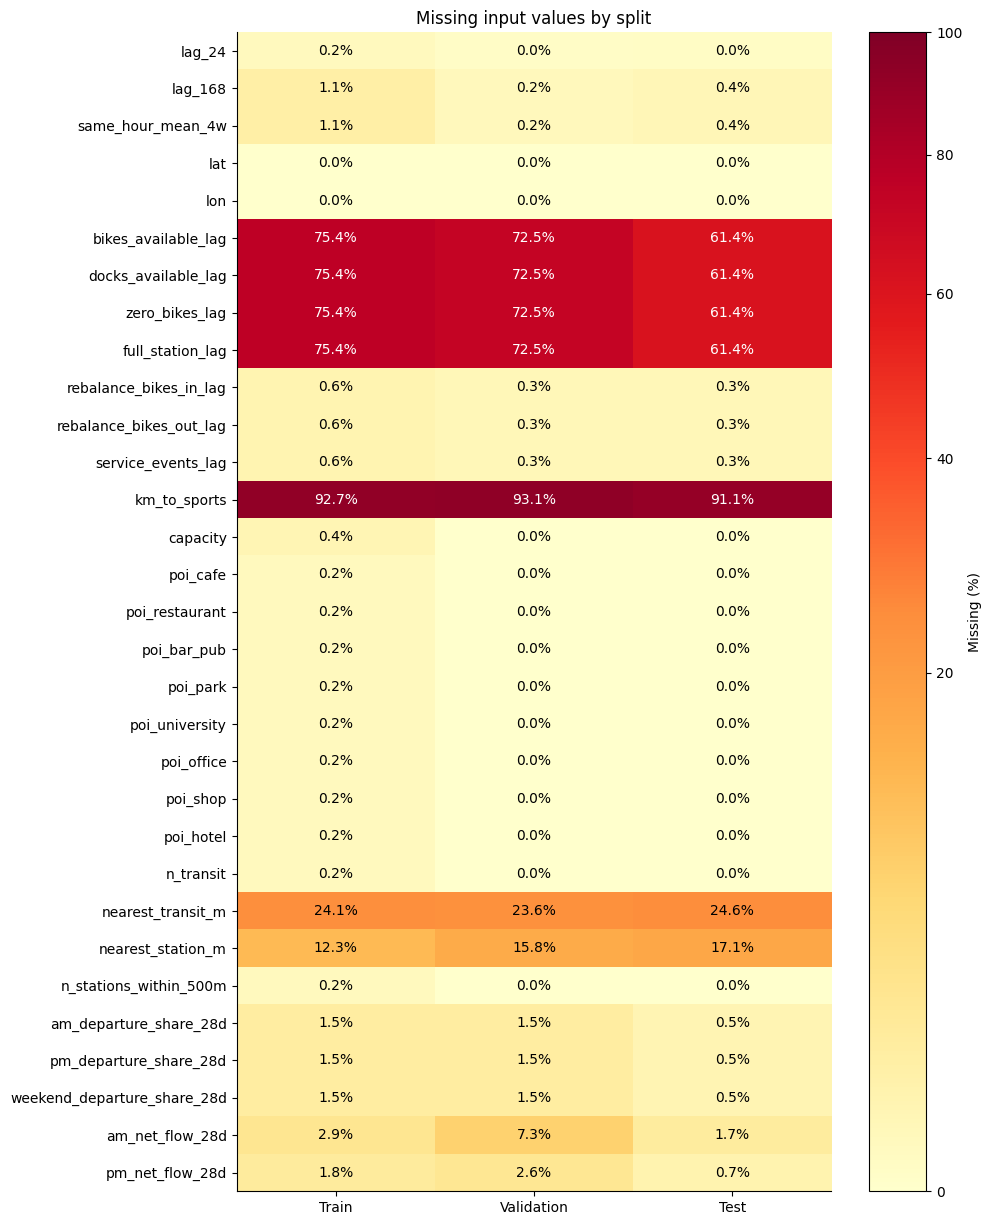

In [ ]:
SEED = 42
MAX_TRAIN_ROWS = 50_000
MAX_FOLD_SCORE_ROWS = 20_000
MAX_ANALYSIS_ROWS = 50_000
N_JOBS = 4
RUN_WINDOW_COMPARISON = True
RUN_SEPTA = True

RESULTS = ROOT / "results" / "supervised"
FIGURES = ROOT / "figures" / "supervised"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Small tuning grids to keep the forward-validation run manageable.
MODEL_GRID = {
    "Poisson": [{"alpha": value} for value in [0.01, 0.1, 1.0]],
    "XGBoost": [
        {"max_depth": depth, "n_estimators": trees}
        for depth in [3, 5] for trees in [100, 200]
    ],
    "Neural network": [
        {"hidden_layer_sizes": (width,), "alpha": alpha, "max_iter": 100}
        for width in [32, 64] for alpha in [0.01, 0.1]
    ],
}

# Forward-validation dates are read from the shared project settings.

summary.to_csv(RESULTS / "input_split_summary.csv", index=False)
missing_by_split.T.to_csv(RESULTS / "input_missingness.csv")
unseen_categories.to_csv(RESULTS / "input_unseen_categories.csv", index=False)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


shown = missing_by_split.loc[:, missing_by_split.max().gt(0)]
fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(shown.columns) + 1.5)))
if shown.shape[1]:
    values = shown.T * 100
    image = ax.imshow(
        values,
        aspect="auto",
        cmap="YlOrRd",
        norm=PowerNorm(gamma=0.5, vmin=0, vmax=100),
    )

    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            value = values.iloc[row, col]
            ax.text(
                col, row, f"{value:.1f}%",
                ha="center", va="center",
                color="white" if value >= 40 else "black",
            )
    ax.set_xticks(range(len(shown)), shown.index)
    ax.set_yticks(range(shown.shape[1]), shown.columns)
    fig.colorbar(image, ax=ax, label="Missing (%)")
else:
    ax.text(0.5, 0.5, "No missing values in the checked inputs", ha="center")
ax.set_title("Missing input values by split")
save_figure(FIGURES / "04_input_coverage.png")

In [ ]:
def score_counts(y, prediction) -> dict:
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    if not len(y) or not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError("Metrics need nonempty, finite targets and predictions")
    return {
        "MAE": float(mean_absolute_error(y, prediction)),
        "RMSE": float(np.sqrt(mean_squared_error(y, prediction))),
        "bias": float(np.mean(prediction - y)),
    }


def checked_prediction(model, frame, columns) -> np.ndarray:
    prediction = np.concatenate([
        np.asarray(model.predict(model_inputs(frame.iloc[start:start + 20_000], columns)), dtype=float)
        for start in range(0, len(frame), 20_000)
    ])
    if not np.isfinite(prediction).all():
        raise RuntimeError("Model produced a nonfinite prediction")
    # Negative counts from the squared-error neural network become zero.
    return np.maximum(prediction, 0)


def take_rows(frame, cap, seed=SEED) -> pd.DataFrame:
    if cap is None or len(frame) <= cap:
        return frame.copy()
    return frame.sample(n=cap, random_state=seed).sort_index().copy()


def model_inputs(frame, columns) -> pd.DataFrame:
    x = frame[columns].copy()
    counts = ["lag_1", "lag_24", "lag_168", "same_hour_mean_4w", "arrivals_lag"]
    for column in columns:
        if column in CATEGORICAL_FEATURES or column == "station_cluster":
            x[column] = x[column].astype("string").fillna("missing").astype(str)
        else:
            x[column] = pd.to_numeric(x[column], errors="coerce").astype(float)
            x[column] = x[column].replace([np.inf, -np.inf], np.nan)
        if column in counts:
            x[column] = np.log1p(x[column].clip(lower=0))
    if "net_flow_lag" in x:
        x["net_flow_lag"] = np.sign(x["net_flow_lag"]) * np.log1p(x["net_flow_lag"].abs())
    for column, period in [("hour_of_day", 24), ("day_of_week", 7), ("month", 12)]:
        if column in x:
            x[column + "_sin"] = np.sin(2 * np.pi * x[column] / period)
            x[column + "_cos"] = np.cos(2 * np.pi * x[column] / period)
    return x


def make_model(family, params, columns, seed=SEED, missing_strategy="median") -> Pipeline:
    categories = [column for column in columns if column in CATEGORICAL_FEATURES or column == "station_cluster"]
    numeric = [column for column in columns if column not in categories]
    numeric += [column + suffix for column in ["hour_of_day", "day_of_week", "month"]
                if column in columns for suffix in ["_sin", "_cos"]]
    if missing_strategy == "native":
        if family != "XGBoost":
            raise ValueError("Only XGBoost can use the native missing-value option.")
        numeric_transformer = "passthrough"
    else:
        if missing_strategy not in ("median", "zero"):
            raise ValueError(f"Unknown missing-value method: {missing_strategy}")
        fill = (SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
                if missing_strategy == "median" else
                SimpleImputer(strategy="constant", fill_value=0, add_indicator=True,
                              keep_empty_features=True))
        steps = [("impute", fill)]
        if family != "XGBoost":
            steps.append(("scale", StandardScaler()))
        numeric_transformer = Pipeline(steps)
    transformers = [("numeric", numeric_transformer, numeric)]
    if categories:
        transformers.append(("category", OneHotEncoder(handle_unknown="ignore", dtype=np.float32), categories))
    # Dense output makes XGBoost treat real zeros equally under all three methods.
    # Otherwise sparse implicit zeros can be mistaken for missing values.
    preprocessing = ColumnTransformer(transformers, sparse_threshold=0.0 if family == "XGBoost" else 1.0)
    if family == "Poisson":
        estimator = PoissonRegressor(max_iter=300, tol=1e-5, **params)
    elif family == "XGBoost":
        estimator = XGBRegressor(
            objective="count:poisson", tree_method="hist", learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9, reg_lambda=5,
            n_jobs=N_JOBS, random_state=seed, **params,
        )
    elif family == "Neural network":
        estimator = MLPRegressor(
            solver="adam", batch_size=1024, learning_rate_init=0.001,
            early_stopping=False, random_state=seed, **params,
        )
    else:
        raise ValueError(f"Unknown family: {family}")
    return Pipeline([("prepare", preprocessing), ("model", estimator)])


def fit_model(family, params, fitting, columns, seed=SEED, missing_strategy="median"):
    model = make_model(family, params, columns, seed, missing_strategy)
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        from threadpoolctl import threadpool_limits
        with threadpool_limits(limits=4):
            model.fit(model_inputs(fitting, columns), fitting["y"])
    notes = sorted(set(str(item.message) for item in caught))
    return model, time.perf_counter() - started, " | ".join(notes)

class HistoricalBaseline:
    def fit(self, frame):
        keys = ["station_id", "day_of_week", "hour_of_day"]
        self.station_mean = frame.groupby(keys, observed=True)["y"].mean()
        self.city_mean = frame.groupby(["day_of_week", "hour_of_day"], observed=True)["y"].mean()
        self.mean = float(frame["y"].mean())
        return self

    def predict(self, frame):
        keys = pd.MultiIndex.from_frame(frame[["station_id", "day_of_week", "hour_of_day"]])
        local = self.station_mean.reindex(keys).to_numpy()
        city_keys = pd.MultiIndex.from_frame(frame[["day_of_week", "hour_of_day"]])
        city = self.city_mean.reindex(city_keys).to_numpy()
        return np.where(np.isfinite(local), local, np.where(np.isfinite(city), city, self.mean))


def baseline_predictions(fitted, frame) -> dict:
    average = fitted.predict(frame)
    return {
        "Station weekday hour mean": average,
        "Same hour previous week": frame["baseline_week"].fillna(pd.Series(average, index=frame.index)).to_numpy(),
        "Previous four weeks mean": frame["baseline_4w"].fillna(pd.Series(average, index=frame.index)).to_numpy(),
    }

def make_window(hours=1, source=None) -> pd.DataFrame:
    if hours not in [1, 2, 3, 4]:
        raise ValueError("Use a 1-, 2-, 3- or 4-hour window")
    frame = (model_frame if source is None else source).copy(deep=False)
    if source is None:
        counts = count_history
    else:
        counts = source.set_index(["station_id", "target_hour"])["y"]
    def at(step):
        keys = pd.MultiIndex.from_arrays([frame.station_id, frame.target_hour + pd.Timedelta(hours=step)])
        return pd.Series(counts.reindex(keys).to_numpy(), index=frame.index)
    frame["y"] = pd.concat([at(step) for step in range(hours)], axis=1).sum(axis=1, min_count=hours)
    week_totals = []
    for week in range(1, 5):
        past = [at(step - 168 * week) for step in range(hours)]
        week_totals.append(pd.concat(past, axis=1).sum(axis=1, min_count=hours))
    frame["baseline_week"] = week_totals[0]
    frame["baseline_4w"] = pd.concat(week_totals, axis=1).mean(axis=1)
    # Match historical counts to the size of the target window.
    yesterday = [at(step - 24) for step in range(hours)]
    frame["lag_24"] = pd.concat(yesterday, axis=1).sum(axis=1, min_count=hours)
    frame["lag_168"] = frame["baseline_week"]
    frame["same_hour_mean_4w"] = frame["baseline_4w"]
    frame["same_hour_weeks"] = pd.concat(week_totals, axis=1).notna().sum(axis=1).astype("int8")
    frame["target_end"] = frame["target_hour"] + pd.Timedelta(hours=hours)
    frame["baseline_lag_168"] = frame["baseline_week"]
    fifa_hours = pd.Series(False, index=frame.index)
    fifa_days = pd.Series(False, index=frame.index)
    for step in range(hours):
        target = frame["target_hour"] + pd.Timedelta(hours=step)
        fifa_hours |= target.isin(match_hours)
        fifa_days |= target.dt.normalize().isin(FIFA_DAYS)
    frame["is_fifa_match_hour"] = fifa_hours
    frame["is_fifa_match_day"] = fifa_days
    frame["is_septa_service_cut"] = frame.target_hour.le(SEPTA_CUT_END) & frame.target_end.gt(SEPTA_CUT_START)
    return frame if frame["y"].notna().all() else frame.loc[frame["y"].notna()]


def time_parts(frame, start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    fitting = frame.loc[frame["target_end"].le(start)]
    scoring = frame.loc[frame["target_hour"].ge(start) & frame["target_end"].le(end)]
    if fitting.empty or scoring.empty:
        raise ValueError(f"No rows for temporal fold {start} to {end}")
    if not fitting["target_end"].le(scoring["target_hour"].min()).all():
        raise RuntimeError("A fitting target crosses the validation boundary")
    return fitting, scoring

# Small timing check: no station borrowing, incomplete targets or crossed boundaries.
check = pd.DataFrame({
    "station_id": np.repeat([1, 2], 800),
    "target_hour": list(pd.date_range("2024-01-01", periods=800, freq="h")) * 2,
    "y": np.r_[np.arange(800), np.arange(800) + 1000],
})
check_window = make_window(3, source=check)
assert check_window.loc[700, "y"] == 700 + 701 + 702
assert check_window.loc[700, "lag_24"] == 676 + 677 + 678
assert check_window.loc[700, "lag_168"] == 532 + 533 + 534
assert check_window.loc[1500, "y"] == 1700 + 1701 + 1702
assert 798 not in check_window.index and 799 not in check_window.index
assert check.loc[700, "y"] == 700  # Building a window must not overwrite the original counts.
gap_check = make_window(3, source=check.drop(index=701)) # Use three hours as a convienient example.
assert 700 not in gap_check.index
check_train, check_val = time_parts(check_window, "2024-01-20", "2024-02-01")
assert check_train.target_end.le(check_val.target_hour.min()).all()
# Changing observations inside a future target may change y, but not its past-count inputs.
for width in [1, 2, 3, 4]:
    before = make_window(width, source=check)
    changed = check.copy()
    changed.loc[700:703, "y"] += 5000
    after = make_window(width, source=changed)
    assert after.loc[700, "y"] == before.loc[700, "y"] + 5000 * width
    assert np.allclose(before.loc[700, ["lag_24", "lag_168", "same_hour_mean_4w"]].astype(float),
                       after.loc[700, ["lag_24", "lag_168", "same_hour_mean_4w"]].astype(float))
# A gap between two valid timestamps must not erase an otherwise available daily lag.
gap_daily = make_window(1, source=check.drop(index=690))
assert gap_daily.loc[700, "lag_24"] == 676

del check, check_window, gap_check, check_train, check_val, before, after, changed, gap_daily


one_hour = make_window(1)
# Each station's last recorded hour has no next-hour target.

model_frame = one_hour.drop(columns=["target_end", "baseline_week", "baseline_4w"]).copy()

## 5. Forward validation

Each fold trains on earlier months and predicts a later period. Use the same sampled forecast starts for every model so comparisons are fair. Select a setting for each model family using average MAE across folds. These folds are used for tuning. The final test quarter is held back.

In [ ]:
def compare_models(frame, columns, windows=CV_WINDOWS, common_rows=None):
    rows = []
    for fold, (start, end) in enumerate(windows, 1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        fit_mask = frame.target_end.le(start_date)
        score_mask = frame.target_hour.ge(start_date) & frame.target_end.le(end_date)
        fit_index = take_rows(frame.loc[fit_mask, ["station_id"]], MAX_TRAIN_ROWS, SEED + fold).index
        score_index = (common_rows[fold] if common_rows is not None else
                       take_rows(frame.loc[score_mask, ["station_id"]], MAX_FOLD_SCORE_ROWS, SEED + fold).index)
        needed = list(dict.fromkeys(columns + ["y", "station_id", "day_of_week", "hour_of_day", "baseline_week", "baseline_4w"]))
        fit_sample = frame.loc[fit_index, needed].copy()
        score_sample = frame.loc[score_index, needed].copy()
        baseline_rows = frame.loc[fit_mask, ["station_id", "day_of_week", "hour_of_day", "y"]]
        baseline = HistoricalBaseline().fit(baseline_rows)
        baseline_count = len(baseline_rows)
        del baseline_rows
        for name, prediction in baseline_predictions(baseline, score_sample).items():
            rows.append({"fold": fold, "family": name, "setting": "baseline", "params": "{}",
                         "fit_rows": baseline_count, "score_rows": len(score_sample), "fit_seconds": 0.0,
                         "warning": "", **score_counts(score_sample.y, prediction)})
        for family, settings in MODEL_GRID.items():
            for number, params in enumerate(settings):
                model, elapsed, note = fit_model(family, params, fit_sample, columns)
                metrics = score_counts(score_sample.y, checked_prediction(model, score_sample, columns))
                rows.append({"fold": fold, "family": family, "setting": str(number),
                             "params": json.dumps(params), "fit_rows": len(fit_sample),
                             "score_rows": len(score_sample), "fit_seconds": elapsed,
                             "warning": note, **metrics})
                del model
        del fit_sample, score_sample
        gc.collect()
    return pd.DataFrame(rows)


def choose_settings(results):
    table = results.groupby(["family", "setting"], as_index=False).agg(
        MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
        fit_seconds_mean=("fit_seconds", "mean"),
    ).sort_values("MAE_mean")
    params, chosen = {}, []
    for family, settings in MODEL_GRID.items():
        row = table.loc[table.family.eq(family)].iloc[0]
        params[family] = deepcopy(settings[int(row.setting)])
        chosen.append(row)
    summary = pd.concat([pd.DataFrame(chosen), table.loc[table.setting.eq("baseline")]])
    summary = summary.sort_values("MAE_mean") # Choose settings by mean MAE.
    family = summary.loc[summary.family.isin(MODEL_GRID)].iloc[0].family
    return table, params, summary, family

# Match forecast starts across windows. Four-hour targets must finish inside the fold.
common_rows = {}
longest = make_window(4)
for fold, (start, end) in enumerate(CV_WINDOWS, 1):
    valid = longest.target_hour.ge(pd.Timestamp(start)) & longest.target_end.le(pd.Timestamp(end))
    common_rows[fold] = take_rows(longest.loc[valid, ["station_id"]], MAX_FOLD_SCORE_ROWS, SEED + fold).index
    assert len(common_rows[fold]) > 0
del longest
cv_results = compare_models(one_hour, FEATURE_COLUMNS, common_rows=common_rows)
cv_summary, best_params, best_cv, best_family = choose_settings(cv_results)
cv_results.to_csv(RESULTS / "one_hour_cv_folds.csv", index=False)
best_cv.to_csv(RESULTS / "one_hour_cv_summary.csv", index=False)
display(best_cv[["family", "MAE_mean", "MAE_std", "RMSE_mean"]].round(3))

## 6. Choose the prediction window

Compare totals over 1, 2, 3 or 4 hours. Note: A two-hour forecast is a total for the next two hours, not a forecast made two hours ahead. Larger windows naturally have larger counts, so compare each model to a historical baseline for the **same** window. We will choose the lowest average model-to-baseline MAE ratio. Ties go to the shorter window.

In [ ]:
window_rows = []
window_tables = []
window_choices = []
window_models = {}
hours_to_try = [1, 2, 3, 4] if RUN_WINDOW_COMPARISON else [1]
for hours in hours_to_try:
    frame = one_hour if hours == 1 else make_window(hours)
    results = (cv_results.copy() if hours == 1 else
               compare_models(frame, FEATURE_COLUMNS, common_rows=common_rows))
    settings, params, family_scores, family = choose_settings(results)
    window_models[hours] = (params, family)
    results["hours"] = hours
    window_tables.append(results)
    selected_setting = str(MODEL_GRID[family].index(params[family]))
    for fold in range(1, len(CV_WINDOWS) + 1):
        part = results.loc[results.fold.eq(fold)]
        best_baseline = part.loc[part.setting.eq("baseline")].sort_values("MAE").iloc[0]
        chosen = part.loc[part.family.eq(family) & part.setting.eq(selected_setting)].iloc[0]
        ratio = chosen.MAE / best_baseline.MAE if best_baseline.MAE else np.nan
        window_rows.append({
            "hours": hours, "fold": fold, "model": family, "MAE": chosen.MAE,
            "RMSE": chosen.RMSE, "MAE_per_hour": chosen.MAE / hours,
            "zero_share": float(frame.loc[common_rows[fold], "y"].eq(0).mean()),
            "mean_departures": float(frame.loc[common_rows[fold], "y"].mean()),
            "baseline": best_baseline.family, "baseline_MAE": best_baseline.MAE,
            "relative_MAE": ratio, "score_rows": chosen.score_rows,
        })
    window_choices.append({"hours": hours, "family": family, "params": json.dumps(params[family])})
    if hours != 1:
        del frame
    gc.collect()
window_results = pd.DataFrame(window_rows)
if window_results.relative_MAE.isna().any():
    raise ValueError("A zero-error baseline makes the window ratio undefined. Inspect the fold before choosing.")
window_summary = window_results.groupby("hours", as_index=False).agg(
    MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"), RMSE_mean=("RMSE", "mean"),
    MAE_per_hour=("MAE_per_hour", "mean"), relative_MAE=("relative_MAE", "mean"),
    relative_MAE_std=("relative_MAE", "std"),
    zero_share=("zero_share", "mean"), mean_departures=("mean_departures", "mean"),
).merge(pd.DataFrame(window_choices), on="hours", validate="one_to_one")
choice = window_summary.sort_values(["relative_MAE", "hours"]).iloc[0]
SELECTED_WINDOW_HOURS = int(choice.hours)
all_window_cv = pd.concat(window_tables, ignore_index=True)
cv_results = all_window_cv.loc[all_window_cv.hours.eq(SELECTED_WINDOW_HOURS)].copy()
cv_summary, best_params, best_cv, best_family = choose_settings(cv_results)
selected_frame = make_window(SELECTED_WINDOW_HOURS)
for table in [cv_results, cv_summary, best_cv]:
    table["window_hours"] = SELECTED_WINDOW_HOURS
for table, name in [(all_window_cv, "all_window_tuning"), (window_results, "prediction_windows"),
                    (window_summary, "window_summary"), (cv_results, "cv_folds"),
                    (cv_summary, "cv_settings"), (best_cv, "cv_family_summary")]:
    table.to_csv(RESULTS / f"{name}.csv", index=False)
display(window_summary[["hours", "family", "MAE_mean", "MAE_per_hour",
                        "relative_MAE", "relative_MAE_std"]].round(3))
print(f"Selected: {SELECTED_WINDOW_HOURS}-hour window; {best_family}.")

# One plot compares windows relative to each window's historical baseline.
fig, ax = plt.subplots(figsize=(8, 4))
for fold, part in window_results.groupby("fold"):
    ax.plot(part.hours, part.relative_MAE, marker="o", alpha=0.5, label=f"Fold {fold}")
ax.plot(window_summary.hours, window_summary.relative_MAE, color="black",
        linewidth=2.2, marker="o", label="Mean")
ax.axhline(1, color="grey", linestyle="--")
ax.set(xlabel="Forecast window (hours)", ylabel="Model MAE / best baseline MAE",
       title="Prediction window comparison", xticks=hours_to_try)
ax.legend(fontsize=8, ncol=2)
save_figure(FIGURES / "06_window_comparison.png")

warnings_table = all_window_cv.loc[all_window_cv.warning.ne(""),
                                    ["hours", "fold", "family", "setting", "warning"]]
warnings_table.to_csv(RESULTS / "training_warnings.csv", index=False)

## 7. Does the way we fill missing values matter?

For XGBoost, compare median filling, zero filling and leaving numeric gaps as `NaN` so XGBoost handles them itself. Median and zero filling both keep a missing-value indicator. All three use the **same folds, rows, features and tuned XGBoost settings**. We compare all three on the same folds used above, then reconsider the model family if XGBoost improves enough to overtake the original winner. Poisson and the neural network keep median filling because they do not accept raw numeric `NaN` values.

In [ ]:
# Compare three ways of handling missing numeric values in XGBoost.
# Categorical nulls are a separate "missing" level for all three runs.
missing_rows = []
for fold, (start, end) in enumerate(CV_WINDOWS, 1):
    fit_mask = selected_frame.target_end.le(pd.Timestamp(start))
    fit_index = take_rows(selected_frame.loc[fit_mask, ["station_id"]],
                          MAX_TRAIN_ROWS, SEED + fold).index
    score_index = common_rows[fold]
    fitting = selected_frame.loc[fit_index]
    scoring = selected_frame.loc[score_index]
    for strategy in ["median", "zero", "native"]:
        model, seconds, note = fit_model(
            "XGBoost", best_params["XGBoost"], fitting, FEATURE_COLUMNS,
            missing_strategy=strategy,
        )
        missing_rows.append({
            "fold": fold, "method": strategy, "fit_seconds": seconds,
            "warning": note,
            **score_counts(scoring.y, checked_prediction(model, scoring, FEATURE_COLUMNS)),
        })
        del model
missing_cv = pd.DataFrame(missing_rows)
missing_summary = (missing_cv.groupby("method", as_index=False)
                   .agg(MAE=("MAE", "mean"), MAE_sd=("MAE", "std"),
                        RMSE=("RMSE", "mean"))
                   .sort_values("MAE"))
XGB_MISSING_MODE = str(missing_summary.iloc[0].method)
# The original family search used median filling. Reconsider XGBoost if its
# better missing-value handling moves it ahead on the same validation folds.
median_search_winner = best_family
original_mae = float(best_cv.loc[best_cv.family.eq(best_family), "MAE_mean"].iloc[0])
if float(missing_summary.iloc[0].MAE) < original_mae:
    best_family = "XGBoost"
missing_cv.to_csv(RESULTS / "xgb_missing_methods_folds.csv", index=False)
missing_summary.to_csv(RESULTS / "xgb_missing_methods_summary.csv", index=False)
display(missing_summary.round(3))
print(f"Final model family: {best_family}; XGBoost missing values: {XGB_MISSING_MODE}.")

## 8. Small checks based on EDA

EDA found strong weather patterns, local sports effects near venues, and incomplete bike-status readings. Compare those feature groups on the same January–March validation rows. These are checks of predictive value, not evidence that events or empty docks cause changes in ridership. The main feature set stays unchanged here.

In [ ]:
# Use the same fitted model and validation rows to compare selected EDA ideas.
fitting, validation = time_parts(selected_frame, TRAIN_END, VAL_END)
train_index = take_rows(fitting[["station_id"]], MAX_TRAIN_ROWS).index
val_index = take_rows(validation[["station_id"]], MAX_ANALYSIS_ROWS).index
analysis_train = selected_frame.loc[train_index]
analysis_val = selected_frame.loc[val_index]
EDA_FEATURE_SETS = {
    "Main features": FEATURE_COLUMNS,
    "No prior-hour weather": [c for c in FEATURE_COLUMNS if c not in WEATHER_FEATURES],
    "Plus nearby sports": list(dict.fromkeys(FEATURE_COLUMNS + SPORTS_FEATURES)),
    "Plus last observed bike status": list(dict.fromkeys(
        FEATURE_COLUMNS + list(PREVIOUS_HOUR_STATUS.values())[:4] + ["status_observed"])),
}
eda_rows = []
for name, columns in EDA_FEATURE_SETS.items():
    mode = XGB_MISSING_MODE if best_family == "XGBoost" else "median"
    model, seconds, note = fit_model(best_family, best_params[best_family],
                                     analysis_train, columns, missing_strategy=mode)
    eda_rows.append({"features": name, "warning": note,
                     **score_counts(analysis_val.y, checked_prediction(model, analysis_val, columns))})
    del model
eda_results = pd.DataFrame(eda_rows)
eda_results["MAE_change"] = eda_results.MAE - eda_results.loc[
    eda_results.features.eq("Main features"), "MAE"].iloc[0]
eda_results.to_csv(RESULTS / "eda_feature_checks.csv", index=False)
display(eda_results[["features", "MAE", "MAE_change", "RMSE"]].round(3))
del analysis_train, analysis_val, fitting, validation

## 9. Do the riding-pattern features help?

Supervised learning suggested distinct morning, evening and weekend behavior. Compare the main model with and without the new 28-day station summaries on identical forward-validation rows. We will only keep them for the primary test model if average fold MAE improves.

In [ ]:
BEHAVIOR_SETS = {
    "Main features": FEATURE_COLUMNS,
    "Main + recent behavior": FEATURE_COLUMNS + BEHAVIOR_FEATURES,
}

behavior_rows = []
for fold, (start, end) in enumerate(CV_WINDOWS, 1):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    train_mask = selected_frame.target_end.le(start)
    train_idx = take_rows(selected_frame.loc[train_mask, ["station_id"]], MAX_TRAIN_ROWS, SEED + fold).index
    score_idx = common_rows[fold]
    for label, columns in BEHAVIOR_SETS.items():
        fitted, elapsed, note = fit_model(best_family, best_params[best_family],
                                          selected_frame.loc[train_idx], columns,
                                          missing_strategy=(XGB_MISSING_MODE if best_family == "XGBoost" else "median"))
        score = selected_frame.loc[score_idx]
        prediction = checked_prediction(fitted, score, columns)
        behavior_rows.append({
            "fold": fold, "features": label, "family": best_family,
            "fit_rows": len(train_idx), "score_rows": len(score_idx),
            "fit_seconds": elapsed, "warning": note,
            **score_counts(score.y, prediction),
        })
        del fitted

behavior_cv = pd.DataFrame(behavior_rows)
behavior_summary = (behavior_cv.groupby("features", as_index=False)
                    .agg(MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
                         RMSE_mean=("RMSE", "mean"))
                    .sort_values("MAE_mean"))
main_mae = behavior_summary.loc[behavior_summary.features.eq("Main features"), "MAE_mean"].iloc[0]
behavior_mae = behavior_summary.loc[behavior_summary.features.eq("Main + recent behavior"), "MAE_mean"].iloc[0]
USE_BEHAVIOR = bool(behavior_mae < main_mae)
SELECTED_FEATURES = (BEHAVIOR_SETS["Main + recent behavior"] if USE_BEHAVIOR else FEATURE_COLUMNS)
display(behavior_summary[["features", "MAE_mean", "MAE_std", "RMSE_mean"]].round(3))
behavior_cv.to_csv(RESULTS / "behavior_cv_folds.csv", index=False)
behavior_summary.to_csv(RESULTS / "behavior_cv_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
control = behavior_cv.loc[behavior_cv.features.eq("Main features")].set_index("fold").MAE
added = behavior_cv.loc[behavior_cv.features.eq("Main + recent behavior")].set_index("fold").MAE
change = added - control
ax.bar(change.index.astype(str), change.values)
ax.axhline(0, color="grey", linestyle="--")
ax.set(xlabel="Validation fold", ylabel="MAE change (negative is better)",
       title="Added 28-day station behavior")
save_figure(FIGURES / "13_behavior_validation.png")

## 10. Final held-out test

Refit the chosen settings on the original training period, then evaluate April–June 2026 once. Report baselines and all model families. The model family, its missing-value method and the behavior feature choice all come from validation, not whichever version wins on the test set.

In [ ]:
# Preserve the original train/validation split: do not refit on January–March 2026.
final_train_mask = selected_frame.target_end.le(TRAIN_END)
final_train = selected_frame.loc[final_train_mask, ["station_id", "day_of_week", "hour_of_day", "y"]]
final_test = selected_frame.loc[selected_frame.target_hour.ge(VAL_END) &
                                selected_frame.target_end.le(TEST_END)]
fit_indices = take_rows(selected_frame.loc[final_train_mask, ["station_id"]], MAX_TRAIN_ROWS).index
final_fit = selected_frame.loc[fit_indices, list(dict.fromkeys(FEATURE_COLUMNS + BEHAVIOR_FEATURES + ["y"]))].copy()
final_baseline = HistoricalBaseline().fit(final_train)
final_predictions = baseline_predictions(final_baseline, final_test)
main_baseline_name = best_cv.loc[best_cv.setting.eq("baseline")].sort_values("MAE_mean").iloc[0].family
final_rows = []
for family, params in best_params.items():
    mode = XGB_MISSING_MODE if family == "XGBoost" else "median"
    model, elapsed, note = fit_model(family, params, final_fit, FEATURE_COLUMNS,
                                     missing_strategy=mode)
    started = time.perf_counter()
    prediction = checked_prediction(model, final_test, FEATURE_COLUMNS)
    predict_seconds = time.perf_counter() - started
    final_predictions[family] = prediction
    final_rows.append({"model": family, "missing_method": mode,
                       "fit_rows": len(final_fit), "test_rows": len(final_test),
                       "fit_seconds": elapsed, "predict_seconds": predict_seconds, "warning": note,
                       **score_counts(final_test.y, prediction)})
    del model
# Score the behavioral version even if validation selected the simpler model.
behavior_model_name = f"{best_family} + recent behavior"
behavior_model, elapsed, note = fit_model(best_family, best_params[best_family],
                                           final_fit, FEATURE_COLUMNS + BEHAVIOR_FEATURES,
                                           missing_strategy=(XGB_MISSING_MODE if best_family == "XGBoost" else "median"))
started = time.perf_counter()
final_predictions[behavior_model_name] = checked_prediction(
    behavior_model, final_test, FEATURE_COLUMNS + BEHAVIOR_FEATURES
)
final_rows.append({
    "model": behavior_model_name,
    "missing_method": XGB_MISSING_MODE if best_family == "XGBoost" else "median",
    "fit_rows": len(final_fit), "test_rows": len(final_test),
    "fit_seconds": elapsed, "predict_seconds": time.perf_counter() - started,
    "warning": note, **score_counts(final_test.y, final_predictions[behavior_model_name]),
})
del behavior_model
primary_model_name = behavior_model_name if USE_BEHAVIOR else best_family

for name in ["Station weekday hour mean", "Same hour previous week", "Previous four weeks mean"]:
    final_rows.append({"model": name, "missing_method": "not applicable",
                       "fit_rows": len(final_train), "test_rows": len(final_test),
                       "fit_seconds": 0.0, "predict_seconds": np.nan, "warning": "",
                       **score_counts(final_test.y, final_predictions[name])})
final_summary = pd.DataFrame(final_rows).sort_values("MAE")
final_summary["window_hours"] = SELECTED_WINDOW_HOURS
display(final_summary[["model", "missing_method", "MAE", "RMSE", "bias"]].round(3))
final_summary.to_csv(RESULTS / "test_family_summary.csv", index=False)

errors = final_test[META_COLUMNS].copy()
errors["prediction"] = final_predictions[primary_model_name]
errors["baseline_prediction"] = final_predictions[main_baseline_name]
errors["main_prediction"] = final_predictions[best_family]
errors["behavior_prediction"] = final_predictions[behavior_model_name]
errors["error"] = errors.prediction - errors.y
errors["absolute_error"] = errors.error.abs()
errors["baseline_absolute_error"] = (errors.baseline_prediction - errors.y).abs()
errors["date"] = errors.target_hour.dt.normalize()
errors["hour_of_day"] = errors.target_hour.dt.hour
errors["known_station"] = errors.station_id.isin(final_train.station_id.unique())
errors["high_demand"] = errors.y.ge(final_train.y.quantile(0.95))
errors["prior_weather_missing"] = final_test[WEATHER_FEATURES].isna().any(axis=1)
errors["status_observed"] = final_test.status_observed.eq(1)
errors["short_history"] = final_test.same_hour_weeks.lt(4)
errors.to_parquet(RESULTS / "test_predictions.parquet", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(final_summary.model, final_summary.MAE)
ax.invert_yaxis()
ax.set_xlabel(f"Test MAE per {SELECTED_WINDOW_HOURS}-hour window")
ax.set_title("April–June 2026: evaluate the choices made in validation")
save_figure(FIGURES / "10_test_models.png")

## 11. Where does the model struggle?

Compare errors on zero- and high-demand hours, new stations, missing readings, and World Cup hours near the stadium. EDA found a localized match-day spike, so show near-stadium hours separately rather than treating a citywide flag as a universal effect.

In [ ]:
def slice_table(frame, masks, prediction_column="prediction"):
    rows = []
    for label, mask in masks.items():
        part = frame.loc[mask]
        if part.empty:
            rows.append({"slice": label, "rows": 0})
            continue
        metrics = score_counts(part.y, part[prediction_column])
        baseline = score_counts(part.y, part.baseline_prediction)
        rows.append({"slice": label, "rows": len(part), "dates": part.date.nunique(),
                     "mean_departures": part.y.mean(), "baseline_MAE": baseline["MAE"],
                     "MAE_vs_baseline": metrics["MAE"] / baseline["MAE"] if baseline["MAE"] else np.nan,
                     **metrics})
    return pd.DataFrame(rows)


june = errors.target_hour.dt.month.eq(6)
fifa = errors.is_fifa_match_hour.astype(bool)
near = errors.near_lff.eq(1)
slices = {
    "All test hours": pd.Series(True, index=errors.index),
    "Daytime 06-22": errors.hour_of_day.between(6, 21),
    "Zero departures": errors.y.eq(0),
    "Positive departures": errors.y.gt(0),
    "High demand (training p95 threshold)": errors.high_demand,
    "Known stations": errors.known_station,
    "New stations": ~errors.known_station,
    "Fewer than four observed weekly lags": errors.short_history,
    "Missing prior-hour weather": errors.prior_weather_missing,
    "Prior-hour status observed": errors.status_observed,
    "Prior-hour status missing": ~errors.status_observed,
    "FIFA match hours, near stadium": fifa & near,
    "FIFA match hours, rest of system": fifa & ~near & errors.near_lff.notna(),
    "Other June hours, near stadium": june & ~fifa & near,
    "Other June hours, rest of system": june & ~fifa & ~near & errors.near_lff.notna(),
}
error_slices = slice_table(errors, slices)
error_slices["window_hours"] = SELECTED_WINDOW_HOURS
display(error_slices[["slice", "rows", "MAE", "baseline_MAE", "MAE_vs_baseline"]].round(3))
error_slices.to_csv(RESULTS / "test_error_slices.csv", index=False)

# Paired error difference. Resample seven-day blocks to retain some serial dependence.
# All stations on each sampled day stay together; this is an approximate interval.
daily_errors = errors.groupby("date").agg(
    model_sum=("absolute_error", "sum"), baseline_sum=("baseline_absolute_error", "sum"), n=("y", "size")
)
rng = np.random.default_rng(SEED)
bootstrap = []
for _ in range(1000):
    sample = daily_errors.iloc[np.concatenate([(start + np.arange(7)) % len(daily_errors)
                            for start in rng.integers(0, len(daily_errors), int(np.ceil(len(daily_errors) / 7)))])[:len(daily_errors)]]
    bootstrap.append((sample.model_sum.sum() - sample.baseline_sum.sum()) / sample.n.sum())
interval = {
    "MAE_difference": float(errors.absolute_error.mean() - errors.baseline_absolute_error.mean()),
    "low_95": float(np.quantile(bootstrap, 0.025)),
    "high_95": float(np.quantile(bootstrap, 0.975)),
    "dates": len(daily_errors),
}
display(pd.DataFrame([interval]).round(3))
pd.DataFrame([interval]).to_csv(RESULTS / "paired_daily_interval.csv", index=False)

### Examples worth checking

Select different station-days: the largest underestimate, largest overestimate, a case where the historical baseline is better, and event or short-history cases when available.

In [ ]:
# Examples are selected from test errors, not used to change the model.
case_table = errors.copy()
case_table["baseline_advantage"] = (case_table.absolute_error - case_table.baseline_absolute_error)
case_table["station_day"] = (case_table.station_id.astype(str) + "_" +
                             case_table.target_hour.dt.strftime("%Y-%m-%d"))

example_rules = [
    ("Largest underestimate", case_table.error.lt(0), "absolute_error"),
    ("Largest overestimate", case_table.error.gt(0), "absolute_error"),
    ("Baseline beats the model", case_table.baseline_advantage.gt(0), "baseline_advantage"),
    ("Match hour near stadium", case_table.is_fifa_match_hour.astype(bool) &
     case_table.near_lff.eq(1), "absolute_error"),
    ("Little station history", (~case_table.known_station) | case_table.short_history, "absolute_error"),
]
seen = set()
example_rows = []
for label, condition, criterion in example_rules:
    candidates = case_table.loc[condition].sort_values(criterion, ascending=False)
    candidates = candidates.loc[~candidates.station_day.isin(seen)]
    if candidates.empty:
        continue
    row = candidates.iloc[0]
    seen.add(row.station_day)
    x = final_test.loc[row.name]
    questions = []
    if row.is_fifa_match_hour:
        questions.append("Did the match change demand near this station?")
    if row.short_history or not row.known_station:
        questions.append("Was there enough past demand for this station?")
    if row.y > row.prediction and row.high_demand:
        questions.append("Did a spike exceed the usual hour/week pattern?")
    if row.prior_weather_missing:
        questions.append("Could missing weather affect this prediction?")
    if not questions:
        questions.append("Check weather, station operation and recent demand.")
    station_type = (station_groups.station_cluster.get(row.station_id, "Not grouped in 04")
                    if RUN_STATION_GROUP_ANALYSIS else "Not loaded")
    example_rows.append({
        "case": label, "station_id": row.station_id, "station_name": row.station_name,
        "station_group_from_04": station_type,
        "target_hour": row.target_hour, "observed": row.y,
        "predicted": row.prediction, "baseline": row.baseline_prediction,
        "absolute_error": row.absolute_error,
        "baseline_absolute_error": row.baseline_absolute_error,
        "MAE_difference_vs_baseline": row.baseline_advantage,
        "lag_1": x.lag_1, "lag_24": x.lag_24, "lag_168": x.lag_168,
        "observed_weekly_lags": x.same_hour_weeks,
        "temperature_prev_hour": x.temperature_c_lag,
        "rain_prev_hour": x.precipitation_mm_lag,
        "bike_status_observed": row.status_observed,
        "check_next": " ".join(questions),
    })
failure_examples = pd.DataFrame(example_rows)
failure_examples.to_csv(RESULTS / "failure_examples.csv", index=False)
display(failure_examples[["case", "station_id", "target_hour", "observed",
                          "predicted", "baseline", "absolute_error",
                          "MAE_difference_vs_baseline"]].round(2))

# One example trace, chosen by error rather than by station popularity.
if example_rows:
    station = example_rows[0]["station_id"]
    center = pd.Timestamp(example_rows[0]["target_hour"])
    recent = errors.loc[errors.station_id.eq(station) &
                        errors.target_hour.between(center - pd.Timedelta(hours=24),
                                                   center + pd.Timedelta(hours=24))]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(recent.target_hour, recent.y, label="Observed")
    ax.plot(recent.target_hour, recent.prediction, label="Model")
    ax.plot(recent.target_hour, recent.baseline_prediction, label="Historical baseline", alpha=0.8)
    ax.set(xlabel="Forecast start", ylabel=f"Departures in {SELECTED_WINDOW_HOURS} hour(s)",
           title=f"Station {station}: largest underestimate")
    ax.legend()
    fig.autofmt_xdate()
    save_figure(FIGURES / "failure_example_trace.png")

## 12. Did the features suggested by unsupervised learning help on the test?

This is a held-out check of the feature choice already made in forward validation. A negative MAE difference means the extra 28-day features helped.

In [ ]:
comparison = errors[["station_id", "target_hour", "y", "is_fifa_match_hour", "near_lff"]].copy()
comparison["main_prediction"] = errors["main_prediction"]
comparison["behavior_prediction"] = errors["behavior_prediction"]
comparison["loss_difference"] = (
    (comparison.behavior_prediction - comparison.y).abs()
    - (comparison.main_prediction - comparison.y).abs()
)
comparison.to_parquet(RESULTS / "behavior_test_predictions.parquet", index=False)

# The difference is behavior minus main, so negative values favor the added features.
first_day = comparison.target_hour.min().normalize()
comparison["block"] = ((comparison.target_hour.dt.normalize() - first_day).dt.days // 7)
blocks = comparison.groupby("block").loss_difference.agg(["sum", "size"])
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(blocks), size=(1000, len(blocks)))
bootstrap = (blocks["sum"].to_numpy()[draws].sum(axis=1)
             / blocks["size"].to_numpy()[draws].sum(axis=1))
behavior_interval = pd.DataFrame([{
    "selected_in_validation": "Main + recent behavior" if USE_BEHAVIOR else "Main features",
    "test_MAE_change": comparison.loss_difference.mean(),
    "low_95": np.quantile(bootstrap, 0.025),
    "high_95": np.quantile(bootstrap, 0.975),
    "weekly_blocks": len(blocks),
}])
behavior_interval.to_csv(RESULTS / "behavior_test_interval.csv", index=False)
display(behavior_interval)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Main", "Main + behavior"], [
    score_counts(comparison.y, comparison.main_prediction)["MAE"],
    score_counts(comparison.y, comparison.behavior_prediction)["MAE"],
])
ax.set(ylabel="Test MAE", title="Past 28-day behavior: final test")
save_figure(FIGURES / "14_behavior_test.png")

## 13. Do errors differ by station group from unsupervised learning?

Since those clusters use trips through 2025, they are **not** model features for earlier training dates. Stations without an exported group are shown separately.

In [ ]:
if RUN_STATION_GROUP_ANALYSIS:
    model_stations = pd.Index(errors.station_id.unique())
    matched = model_stations.isin(station_groups.index)
    station_coverage = pd.DataFrame([{
        "test_stations": len(model_stations),
        "stations_grouped_in_04": int(matched.sum()),
        "stations_not_grouped": int((~matched).sum()),
        "groups_exported_by_04": int(station_groups.station_cluster.nunique()),
    }])
    display(station_coverage)
    station_coverage.to_csv(RESULTS / "station_group_coverage.csv", index=False)

In [ ]:
if RUN_STATION_GROUP_ANALYSIS:
    group_errors = errors[["station_id", "target_hour", "y", "prediction",
                           "baseline_prediction", "main_prediction",
                           "behavior_prediction"]].copy()
    group_errors["station_cluster"] = (group_errors.station_id.map(station_groups.station_cluster)
                                       .fillna("Not grouped in 04"))
    group_errors["cluster_confidence"] = group_errors.station_id.map(station_groups.cluster_confidence)
    group_errors["absolute_error"] = (group_errors.prediction - group_errors.y).abs()
    group_errors["baseline_absolute_error"] = (group_errors.baseline_prediction - group_errors.y).abs()
    group_errors["main_absolute_error"] = (group_errors.main_prediction - group_errors.y).abs()
    group_errors["behavior_absolute_error"] = (group_errors.behavior_prediction - group_errors.y).abs()

    by_group = group_errors.groupby("station_cluster", as_index=False).agg(
        rows=("y", "size"), stations=("station_id", "nunique"),
        mean_departures=("y", "mean"),
        selected_MAE=("absolute_error", "mean"),
        baseline_MAE=("baseline_absolute_error", "mean"),
        main_MAE=("main_absolute_error", "mean"),
        behavior_MAE=("behavior_absolute_error", "mean"),
        mean_cluster_confidence=("cluster_confidence", "mean"),
    )
    by_group["behavior_MAE_change"] = by_group.behavior_MAE - by_group.main_MAE
    by_group = by_group.sort_values("selected_MAE")
    by_group.to_csv(RESULTS / "test_errors_by_04_station_group.csv", index=False)
    display(by_group.round(3))

    fig, ax = plt.subplots(figsize=(9, 4))
    positions = np.arange(len(by_group))
    ax.barh(positions - 0.18, by_group.main_MAE, height=0.36, label="Main")
    ax.barh(positions + 0.18, by_group.behavior_MAE, height=0.36, label="Main + behavior")
    ax.set_yticks(positions, by_group.station_cluster)
    ax.set(xlabel="Test MAE", title="Forecast errors by station group from 04")
    ax.invert_yaxis()
    ax.legend()
    save_figure(FIGURES / "16_errors_by_station_group.png")

run_settings = {
    "packages": {name: importlib.metadata.version(name) for name in
                 ["numpy", "pandas", "pyarrow", "scikit-learn", "xgboost", "matplotlib"]},
    "max_train_rows": MAX_TRAIN_ROWS,
    "max_fold_score_rows": MAX_FOLD_SCORE_ROWS,
    "shared_manifest_hash": file_hash(SHARED / "shared_manifest.json"),
    "station_clusters_manifest_hash": (file_hash(EXPORTS / "station_clusters_manifest.json")
                                       if RUN_STATION_GROUP_ANALYSIS else None),
    "station_groups_from_04": (station_manifest.get("cluster_names")
                                if RUN_STATION_GROUP_ANALYSIS else None),
    "xgb_missing_method": XGB_MISSING_MODE,
    "selected_family": best_family,
    "median_search_winner": median_search_winner,
    "selected_feature_set": "Main + recent behavior" if USE_BEHAVIOR else "Main features",
    "window_hours": SELECTED_WINDOW_HOURS,
    "behavior_window": "28 days ending in the last observed hour",
    "model_search": "all_window_tuning.csv",
    "behavior_comparison": "behavior_cv_folds.csv",
    "test_summary": "test_family_summary.csv",
}
(RESULTS / "run_settings.json").write_text(json.dumps(run_settings, indent=2) + "\n")

## 14. SEPTA period: separate stress test

EDA found that the August–September 2025 service cut followed much of the prior seasonal pattern. To avoid learning from the cut, we will tune a one-hour model on months before August, train before August 24, then compare the cut with the preceding weeks. This is a forecasting stress test, not an estimate of the cut's causal effect.

In [ ]:
if RUN_SEPTA:
    # Select indices first. Only sampled feature rows and four baseline columns
    # are needed; copying the entire earlier table exceeded the memory budget.
    def event_parts(start, end, seed=SEED, score_cap=None):
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        earlier = one_hour.target_end.le(start)
        later = one_hour.target_hour.ge(start) & one_hour.target_end.le(end)
        fit_index = take_rows(one_hour.loc[earlier, ["station_id"]], MAX_TRAIN_ROWS, seed).index
        score_index = take_rows(one_hour.loc[later, ["station_id"]], score_cap, seed).index
        columns = list(dict.fromkeys(FEATURE_COLUMNS + META_COLUMNS + ["target_end"]))
        fitting = one_hour.loc[fit_index, columns].copy()
        scoring = one_hour.loc[score_index, columns].copy()
        assert fitting.target_end.max() <= scoring.target_hour.min()
        return fitting, scoring, earlier

    def event_baseline(earlier, scoring):
        columns = ["station_id", "day_of_week", "hour_of_day", "y"]
        return HistoricalBaseline().fit(one_hour.loc[earlier, columns]).predict(scoring)

    pre_windows = [("2025-05-01", "2025-06-01"), ("2025-06-01", "2025-07-01"), ("2025-07-01", "2025-08-01")]
    pre_rows = []
    for fold, (start, end) in enumerate(pre_windows, 1):
        train_pre, val_pre, _ = event_parts(start, end, SEED + fold, MAX_FOLD_SCORE_ROWS)
        for family, settings in MODEL_GRID.items():
            for number, params in enumerate(settings):
                model, elapsed, note = fit_model(family, params, train_pre, FEATURE_COLUMNS)
                pre_rows.append({"fold": fold, "family": family, "setting": number, "warning": note,
                                 **score_counts(val_pre.y, checked_prediction(model, val_pre, FEATURE_COLUMNS))})
                del model
    pre_cv = pd.DataFrame(pre_rows)
    pre_summary = pre_cv.groupby(["family", "setting"], as_index=False).MAE.mean().sort_values("MAE")
    choice = pre_summary.iloc[0]
    pre_family = choice.family
    pre_params = MODEL_GRID[pre_family][int(choice.setting)]
    cut_end = SEPTA_CUT_END + pd.Timedelta(hours=1)
    pre_train, cut, pre_mask = event_parts(SEPTA_CUT_START, cut_end)
    pre_model, elapsed, note = fit_model(pre_family, pre_params, pre_train, FEATURE_COLUMNS)
    cut_predictions = checked_prediction(pre_model, cut, FEATURE_COLUMNS)
    cut_average = event_baseline(pre_mask, cut)
    comparison_rows = [{"period": "SEPTA cut", "model": pre_family, "rows": len(cut),
                        **score_counts(cut.y, cut_predictions)},
                       {"period": "SEPTA cut", "model": "Station weekday hour mean", "rows": len(cut),
                        **score_counts(cut.y, cut_average)}]
    cut_details = cut[META_COLUMNS].copy()
    cut_details["prediction"] = cut_predictions
    cut_details["baseline_prediction"] = cut_average
    cut_details.to_parquet(RESULTS / "septa_predictions.parquet", index=False)
    for start, end in [("2025-08-03", "2025-08-10"), ("2025-08-10", "2025-08-17"), ("2025-08-17", "2025-08-24")]:
        train_pre, val_pre, earlier = event_parts(start, end)
        model, _, note = fit_model(pre_family, pre_params, train_pre, FEATURE_COLUMNS)
        comparison_rows.append({"period": f"Reference week {start}", "model": pre_family, "rows": len(val_pre),
                                **score_counts(val_pre.y, checked_prediction(model, val_pre, FEATURE_COLUMNS))})
        prediction = event_baseline(earlier, val_pre)
        comparison_rows.append({"period": f"Reference week {start}", "model": "Station weekday hour mean",
                                "rows": len(val_pre), **score_counts(val_pre.y, prediction)})
        del model
    septa_results = pd.DataFrame(comparison_rows)
    septa_results["window_hours"] = 1
    display(septa_results[["period", "model", "rows", "MAE", "RMSE"]].round(3))
    pre_cv.to_csv(RESULTS / "septa_pre_cut_tuning.csv", index=False)
    septa_results.to_csv(RESULTS / "septa_stress_test.csv", index=False)
    del train_pre, val_pre, pre_train, cut, pre_model, cut_details
    gc.collect()